In [2]:
import pandas as pd
import numpy as np

df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')

print("Shape of dataset:", df.shape)
print("\nColumn names:\n", df.columns.tolist())
print("\nData types:\n", df.dtypes)
print("\nFirst 5 rows:\n", df.head())
print("\nBasic statistics:\n", df.describe())

Shape of dataset: (7043, 21)

Column names:
 ['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents', 'tenure', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn']

Data types:
 customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
PaperlessBilling     object
PaymentMethod        object
MonthlyCharges      float64
TotalCharges         object
Churn                object
dtype: object

First 5 rows:


In [3]:
print("Missing values per column:\n", df.isnull().sum())

print("\nNumber of duplicate rows:", df.duplicated().sum())

print("\nData types:\n", df.dtypes)

df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

print("\nMissing values in TotalCharges after conversion:", df['TotalCharges'].isnull().sum())

df = df.dropna(subset=['TotalCharges'])

df = df.drop('customerID', axis=1)

print("\nShape after cleaning:", df.shape)

Missing values per column:
 customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

Number of duplicate rows: 0

Data types:
 customerID           object
gender               object
SeniorCitizen         int64
Partner              object
Dependents           object
tenure                int64
PhoneService         object
MultipleLines        object
InternetService      object
OnlineSecurity       object
OnlineBackup         object
DeviceProtection     object
TechSupport          object
StreamingTV          object
StreamingMovies      object
Contract             object
Paperl

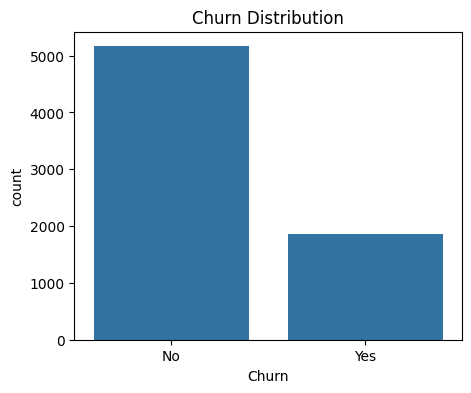

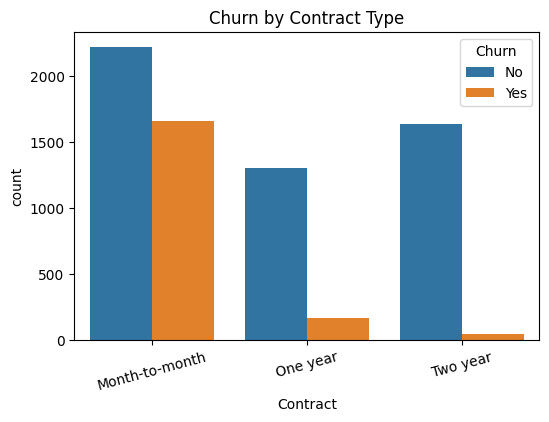

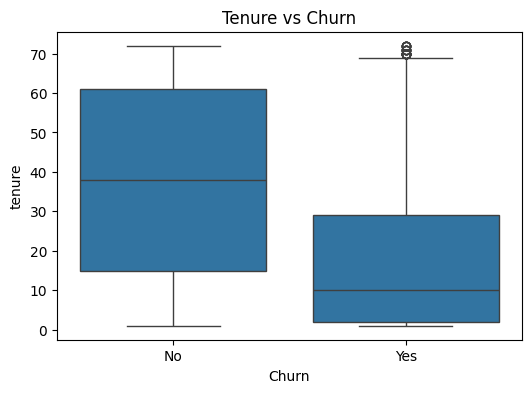

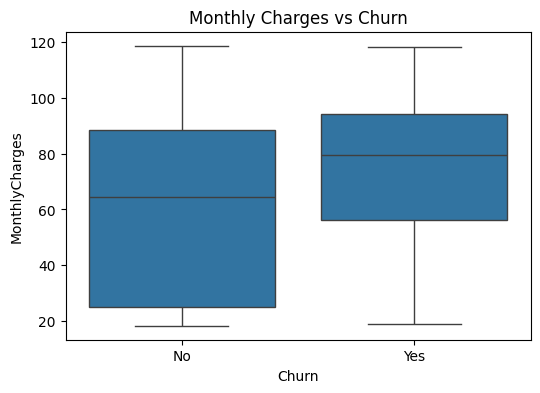

Churn Rate (%):
 Churn
No     73.421502
Yes    26.578498
Name: proportion, dtype: float64


In [4]:
import matplotlib.pyplot as plt
import seaborn as sns

plt.figure(figsize=(5,4))
sns.countplot(x='Churn', data=df)
plt.title('Churn Distribution')
plt.show()

plt.figure(figsize=(6,4))
sns.countplot(x='Contract', hue='Churn', data=df)
plt.title('Churn by Contract Type')
plt.xticks(rotation=15)
plt.show()

plt.figure(figsize=(6,4))
sns.boxplot(x='Churn', y='tenure', data=df)
plt.title('Tenure vs Churn')
plt.show()

plt.figure(figsize=(6,4))
sns.boxplot(x='Churn', y='MonthlyCharges', data=df)
plt.title('Monthly Charges vs Churn')
plt.show()

churn_rate = df['Churn'].value_counts(normalize=True) * 100
print("Churn Rate (%):\n", churn_rate)

In [5]:
y = df['Churn'].map({'Yes': 1, 'No': 0})
X = df.drop('Churn', axis=1)

categorical_cols = X.select_dtypes(include='object').columns.tolist()
print("Categorical columns:", categorical_cols)

X = pd.get_dummies(X, columns=categorical_cols, drop_first=True)

print("Shape of X after encoding:", X.shape)
print(X.head())

Categorical columns: ['gender', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'InternetService', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling', 'PaymentMethod']
Shape of X after encoding: (7032, 30)
   SeniorCitizen  tenure  MonthlyCharges  TotalCharges  gender_Male  \
0              0       1           29.85         29.85        False   
1              0      34           56.95       1889.50         True   
2              0       2           53.85        108.15         True   
3              0      45           42.30       1840.75         True   
4              0       2           70.70        151.65        False   

   Partner_Yes  Dependents_Yes  PhoneService_Yes  \
0         True           False             False   
1        False           False              True   
2        False           False              True   
3        False           False             False   
4        False

In [6]:
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training set shape:", X_train.shape)
print("Testing set shape:", X_test.shape)

log_model = LogisticRegression(max_iter=1000)
log_model.fit(X_train, y_train)

rf_model = RandomForestClassifier(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

print("Both models trained successfully!")

Training set shape: (5625, 30)
Testing set shape: (1407, 30)


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_logistic.py:465: ConvergenceWarning: lbfgs failed to converge (status=1):
STOP: TOTAL NO. OF ITERATIONS REACHED LIMIT.

Increase the number of iterations (max_iter) or scale the data as shown in:
    https://scikit-learn.org/stable/modules/preprocessing.html
Please also refer to the documentation for alternative solver options:
    https://scikit-learn.org/stable/modules/linear_model.html#logistic-regression
  n_iter_i = _check_optimize_result(


Both models trained successfully!


Logistic Regression Results:
Accuracy: 0.8031272210376688
Precision: 0.6465256797583081
Recall: 0.5721925133689839
F1-Score: 0.6070921985815603
Confusion Matrix:
 [[916 117]
 [160 214]]

--- Random Forest Results ---
Accuracy: 0.7896233120113717
Precision: 0.6258064516129033
Recall: 0.5187165775401069
F1-Score: 0.5672514619883041
Confusion Matrix:
 [[917 116]
 [180 194]]


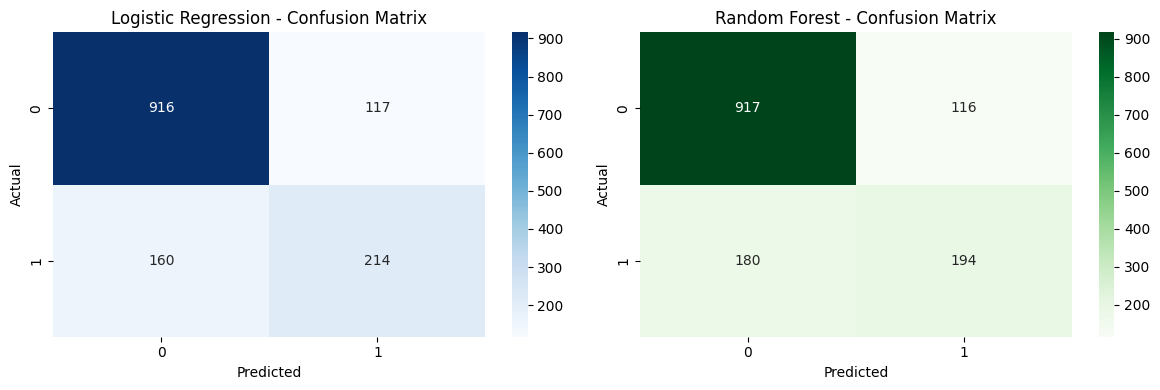

In [7]:
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, classification_report

log_preds = log_model.predict(X_test)
rf_preds = rf_model.predict(X_test)

print("Logistic Regression Results:")
print("Accuracy:", accuracy_score(y_test, log_preds))
print("Precision:", precision_score(y_test, log_preds))
print("Recall:", recall_score(y_test, log_preds))
print("F1-Score:", f1_score(y_test, log_preds))
print("Confusion Matrix:\n", confusion_matrix(y_test, log_preds))

print("\n--- Random Forest Results ---")
print("Accuracy:", accuracy_score(y_test, rf_preds))
print("Precision:", precision_score(y_test, rf_preds))
print("Recall:", recall_score(y_test, rf_preds))
print("F1-Score:", f1_score(y_test, rf_preds))
print("Confusion Matrix:\n", confusion_matrix(y_test, rf_preds))

import seaborn as sns
import matplotlib.pyplot as plt

fig, axes = plt.subplots(1, 2, figsize=(12,4))
sns.heatmap(confusion_matrix(y_test, log_preds), annot=True, fmt='d', ax=axes[0], cmap='Blues')
axes[0].set_title('Logistic Regression - Confusion Matrix')
axes[0].set_xlabel('Predicted')
axes[0].set_ylabel('Actual')

sns.heatmap(confusion_matrix(y_test, rf_preds), annot=True, fmt='d', ax=axes[1], cmap='Greens')
axes[1].set_title('Random Forest - Confusion Matrix')
axes[1].set_xlabel('Predicted')
axes[1].set_ylabel('Actual')

plt.tight_layout()
plt.show()

In [8]:
final_model = log_model

sample_customer = X_test.iloc[[0]]
actual_label = y_test.iloc[0]

prediction = final_model.predict(sample_customer)
prediction_prob = final_model.predict_proba(sample_customer)

print("Sample customer input data:\n", sample_customer)
print("\nActual Churn label:", "Yes" if actual_label == 1 else "No")
print("Predicted Churn:", "Yes" if prediction[0] == 1 else "No")
print("Prediction Probability [No, Yes]:", prediction_prob)

new_customer = X_test.iloc[[5]].copy()
new_prediction = final_model.predict(new_customer)
print("\nNew customer prediction:", "Churn" if new_prediction[0] == 1 else "No Churn")

Sample customer input data:
      SeniorCitizen  tenure  MonthlyCharges  TotalCharges  gender_Male  \
974              0      59           75.95       4542.35        False   

     Partner_Yes  Dependents_Yes  PhoneService_Yes  \
974         True            True              True   

     MultipleLines_No phone service  MultipleLines_Yes  ...  \
974                           False              False  ...   

     StreamingTV_No internet service  StreamingTV_Yes  \
974                            False             True   

     StreamingMovies_No internet service  StreamingMovies_Yes  \
974                                False                 True   

     Contract_One year  Contract_Two year  PaperlessBilling_Yes  \
974              False               True                  True   

     PaymentMethod_Credit card (automatic)  PaymentMethod_Electronic check  \
974                                   True                           False   

     PaymentMethod_Mailed check  
974             